In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt


In [3]:
df = pd.read_csv("Degree 2 Polynomial.csv")

df


,X,Y
0,-2,9
1,-1,2
2,0,1
3,1,6
4,2,17


In [5]:
X = df['X'].values
y = df['Y'].values

print("X:", X)
print("Y:", y)


X: [-2 -1  0  1  2]
Y: [ 9  2  1  6 17]


In [7]:
X_matrix = np.column_stack((X**2, X, np.ones(len(X))))

print("Design Matrix:")
print(X_matrix)


Design Matrix:
[[ 4. -2.  1.]
 [ 1. -1.  1.]
 [ 0.  0.  1.]
 [ 1.  1.  1.]
 [ 4.  2.  1.]]


In [9]:
X_T = X_matrix.T

XTX = X_T @ X_matrix
XTy = X_T @ y

print("X^T X:")
print(XTX)

print("\nX^T y:")
print(XTy)


X^T X:
[[34.  0. 10.]
 [ 0. 10.  0.]
 [10.  0.  5.]]

X^T y:
[112.  20.  35.]


In [11]:
beta = np.linalg.inv(XTX) @ XTy

a, b, c = beta

print("a =", a)
print("b =", b)
print("c =", c)


a = 3.000000000000001
b = 2.0
c = 0.9999999999999982


In [13]:
y_pred = X_matrix @ beta

print("Predicted values:")
print(y_pred)


Predicted values:
[ 9.  2.  1.  6. 17.]


In [15]:
mse = np.mean((y - y_pred)**2)

print("Train MSE:", mse)


Train MSE: 1.5777218104420236e-30


In [17]:
ss_res = np.sum((y - y_pred)**2)
ss_tot = np.sum((y - np.mean(y))**2)

r2 = 1 - (ss_res / ss_tot)

print("R² Score:", r2)


R² Score: 1.0


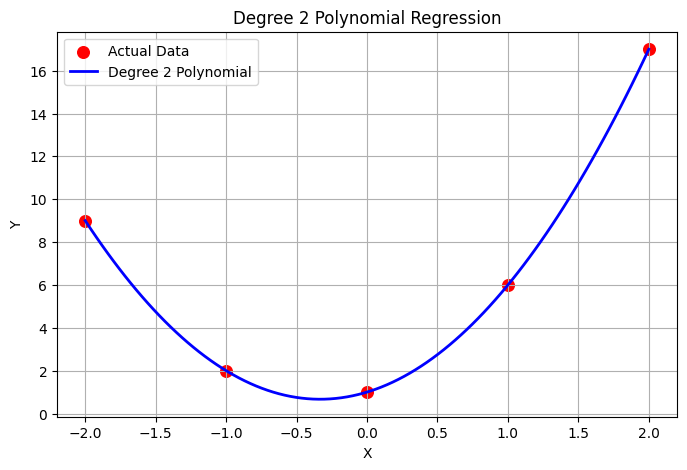

In [19]:
x_curve = np.linspace(X.min(), X.max(), 100)
y_curve = a*x_curve**2 + b*x_curve + c

plt.figure(figsize=(8, 5))

plt.scatter(X, y, color='red', s=70, label='Actual Data')
plt.plot(x_curve, y_curve, color='blue', linewidth=2,
         label='Degree 2 Polynomial')

plt.xlabel('X')
plt.ylabel('Y')
plt.title('Degree 2 Polynomial Regression')
plt.legend()
plt.grid(True)

plt.show()
